# MLP + PyTorch 数字识别实践

## 多层感知机

单层感知机的基础上，在输入和输出层之间加入若干隐藏层，通过激活函数赋予模型非线性。

## pytorch 实践

### 训练流程拆解

1. 引入`torch`库

In [1]:
import torch
print(torch.__version__)

2.14.1+cpu


2. 准备数据（同上节）

In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()
X = digits.data  # 图片展开为了64维的向量，逻辑回归使用向量（若是CNN则使用image矩阵）
y = digits.target  # 结果对应的数字

# 数据集划分
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1437, 64), (360, 64), (1437,), (360,))

3. 将数据转化为torch tensor

In [3]:
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train, dtype=torch.long)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

print(X_train_tensor.shape, X_train_tensor.dtype)
print(y_train_tensor.shape, y_train_tensor.dtype)

torch.Size([1437, 64]) torch.float32
torch.Size([1437]) torch.int64


4. 搭网络

   该MLP结构为$64\to128\to10$，可以使用`nn.Sequential`

In [4]:
import torch.nn as nn

In [5]:
model = nn.Sequential(
    nn.Linear(64, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

In [6]:
logits = model(X_train_tensor)
print(logits, logits.shape)

# 查看model中每一步的函数
z1 = model[0](X_train_tensor)
h = model[1](z1)
logits = model[2](h)

print(z1.grad_fn)
print(h.grad_fn)
print(logits.grad_fn)

tensor([[-0.6484,  0.8579,  1.7653,  ..., -1.3735,  1.6461, -0.4082],
        [ 0.5529,  0.9170,  0.9588,  ..., -1.6515,  0.3583,  0.5170],
        [-2.1223, -1.0680,  1.9583,  ..., -0.3259, -1.2470,  0.6051],
        ...,
        [-0.1363,  0.9570,  0.7677,  ..., -1.5838,  0.2878,  1.7255],
        [-3.8290, -1.2855,  2.2244,  ...,  1.3455, -0.2686,  0.7015],
        [-0.8972,  1.3876,  1.3761,  ..., -0.6871,  1.1198,  0.9826]],
       grad_fn=<AddmmBackward0>) torch.Size([1437, 10])


5. 算loss，用交叉熵损失算法，内部等价于$\text{LogSoftmax}+\text{NLLLoss}$

In [7]:
loss_fn = nn.CrossEntropyLoss()
loss = loss_fn(logits, y_train_tensor)
print(loss)
print(loss.shape)

tensor(3.2137, grad_fn=<NllLossBackward0>)
torch.Size([])


6. 反向传播

In [8]:
print(model[0].weight.grad)   # backward 前通常是 None

loss.backward() # 不返回任何值，但是将梯度写进了参数对象.grad中

print(model[0].weight.grad)
print(model[0].weight.grad.shape)

None
tensor([[ 0.0000e+00,  1.3432e-03,  1.6162e-03,  ...,  1.1948e-02,
          5.1332e-03,  2.7545e-04],
        [ 0.0000e+00,  4.8932e-05, -3.5023e-03,  ..., -1.5580e-02,
         -1.3611e-03,  5.0558e-04],
        [ 0.0000e+00, -9.5726e-03, -9.9124e-02,  ...,  1.6342e-02,
          3.5949e-03,  1.0160e-03],
        ...,
        [ 0.0000e+00,  1.5586e-02,  2.0879e-01,  ...,  9.3645e-02,
         -1.8639e-02, -4.2562e-03],
        [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  ...,  6.2387e-04,
          0.0000e+00,  0.0000e+00],
        [ 0.0000e+00,  1.4242e-05, -2.1850e-02,  ..., -5.4364e-02,
         -5.2638e-03, -8.8478e-04]])
torch.Size([128, 64])


7. 创建优化器，并更新参数

In [9]:
optimizer = torch.optim.SGD(model.parameters(), lr=0.01) # 梯度下降优化法，学习率0.01

before = model[0].weight.clone()
optimizer.step()  # 让优化器自动更新参数
after = model[0].weight

print(torch.equal(before, after)) # False表示参数已经改变

optimizer.zero_grad() # 清空旧的.grad值，为下一轮迭代做准备

False


In [10]:
# parameters() 是一个生成器，其中包含model中所有模型的参数（本模型中依次是 W1, b1, W2, b2）
for p in model.parameters():
    print(p.shape)

torch.Size([128, 64])
torch.Size([128])
torch.Size([10, 128])
torch.Size([10])


In [11]:
print(loss)
logits = model(X_train_tensor)
loss = loss_fn(logits, y_train_tensor)
print(loss)

tensor(3.2137, grad_fn=<NllLossBackward0>)
tensor(2.5171, grad_fn=<NllLossBackward0>)


### 实际训练过程

In [12]:
def train(epochs, lr):
    # 定义模型
    torch.manual_seed(42)
    model = nn.Sequential(
        nn.Linear(64, 128),
        nn.ReLU(),
        nn.Linear(128, 10)
    )
    # 定义损失函数
    loss_fn = nn.CrossEntropyLoss()
    # 定义优化器
    optimizer = torch.optim.SGD(model.parameters(), lr)
    for eopch in range(epochs):
        # 清空旧的梯度
        optimizer.zero_grad()
        # forward
        logits = model(X_train_tensor)
        # 计算损失
        loss = loss_fn(logits, y_train_tensor)
        # 计算各级梯度
        loss.backward()
        # 根据梯度更新参数
        optimizer.step()

        # 打印loss观察
        if eopch % 50 == 0:
            print(loss.item())

    return model

In [13]:
model = train(500, 0.1)

3.3030738830566406
0.07613801211118698
0.0366666354238987
0.023838980123400688
0.017091574147343636
0.013060621917247772
0.010418862104415894
0.008590778335928917
0.00725326593965292
0.00623986404389143


### 测试集测试

In [14]:
with torch.no_grad():
    pred_train = torch.argmax(model(X_train_tensor), dim=1)
    train_acc = (pred_train == y_train_tensor).float().mean()

print(train_acc.item())

with torch.no_grad():
    logits = model(X_test_tensor)
    pred = torch.argmax(logits, dim=1)
    acc = (pred == y_test_tensor).float().mean()

print(acc.item())

1.0
0.980555534362793


### 错误样本查看

tensor([ 36,  51, 127, 140, 228, 233, 325])


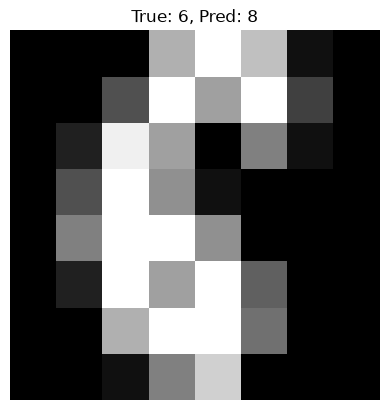

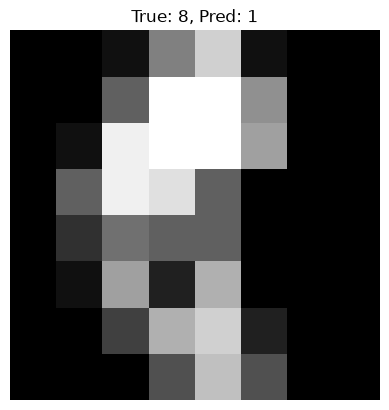

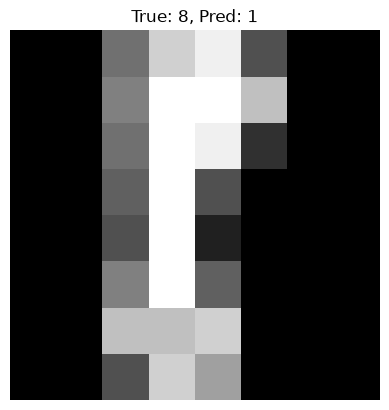

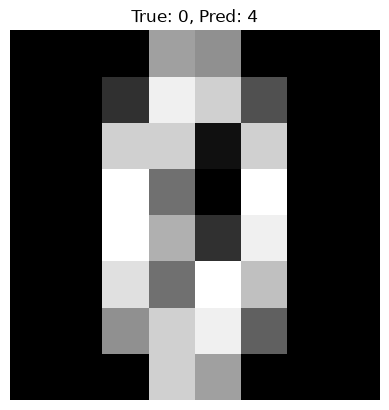

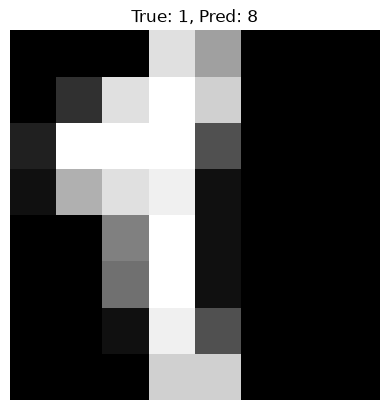

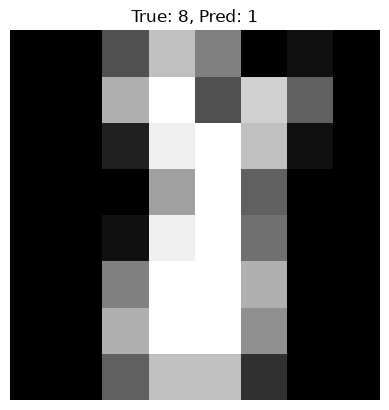

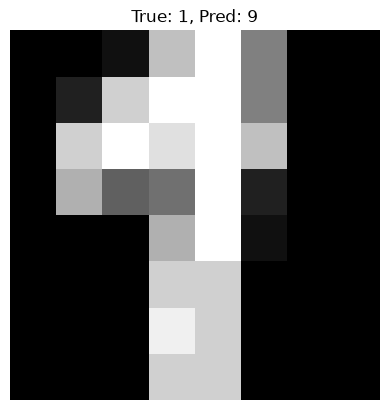

In [15]:
wrong_idx = torch.where(pred != y_test_tensor)[0]
print(wrong_idx)

import matplotlib.pyplot as plt
for idx in wrong_idx:
    plt.figure()
    plt.imshow(X_test_tensor[idx].reshape(8, 8), cmap="gray")
    plt.title(f"True: {y_test_tensor[idx]}, Pred: {pred[idx]}")
    plt.axis("off")
    plt.show()